In [1]:
%pip install -U langchain langchain-ollama langgraph

Note: you may need to restart the kernel to use updated packages.


In [2]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwen2.5:3b",
    temperature=0
)

print("✅ ChatOllama initialized successfully!")

✅ ChatOllama initialized successfully!


In [3]:
import time

start_time = time.time()

response = llm.invoke(
    "Explain what an AI research agent is in exactly 3 bullet points."
)

end_time = time.time()

print("Response:\n")
print(response.content)

print("\n" + "=" * 50)
print(f"Response time: {end_time - start_time:.2f} seconds")

ConnectError: [WinError 10061] No connection could be made because the target machine actively refused it

In [ ]:
from pydantic import BaseModel, Field

class ResearchPlan(BaseModel):
    topic: str = Field(
        description="The main topic being researched"
    )
    
    research_questions: list[str] = Field(
        description="Specific questions that need to be answered"
    )
    
    search_queries: list[str] = Field(
        description="Search queries to use for gathering information"
    )

In [ ]:
planner_llm = llm.with_structured_output(ResearchPlan)

print("✅ Structured planner initialized")

✅ Structured planner initialized


In [ ]:
question = """
Compare LangGraph and AutoGen for building multi-agent AI systems.
"""

plan = planner_llm.invoke(question)

print("TOPIC:")
print(plan.topic)

print("\nRESEARCH QUESTIONS:")
for q in plan.research_questions:
    print("-", q)

print("\nSEARCH QUERIES:")
for q in plan.search_queries:
    print("-", q)

TOPIC:
Comparison of LangGraph and AutoGen for Building Multi-Agent AI Systems

RESEARCH QUESTIONS:
- How do LangGraph and AutoGen differ in their approaches to building multi-agent AI systems?
- What are the key features and functionalities of LangGraph and AutoGen in this context?
- Which tool is more suitable for which type of multi-agent AI system development?
- What are the advantages and disadvantages of using LangGraph and AutoGen for multi-agent AI systems?
- How do LangGraph and AutoGen compare in terms of flexibility, scalability, and customization for multi-agent AI systems?

SEARCH QUERIES:
- LangGraph multi-agent AI systems
- AutoGen multi-agent AI systems
- Comparison of LangGraph and AutoGen for multi-agent AI systems
- LangGraph vs AutoGen in multi-agent AI systems
- LangGraph and AutoGen for multi-agent AI systems


In [ ]:
from langchain_core.prompts import ChatPromptTemplate

planner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """You are an expert AI research planner.

Your job is to convert a user's research request into a clear and efficient research plan.

Rules:
1. Identify the exact main topic.
2. Create 3 to 6 specific research questions.
3. Create useful search queries for finding reliable information.
4. Avoid vague or overly broad questions.
5. Focus on factual, verifiable information.
6. Do not answer the research question yourself.
7. Only create the research plan.
"""
    ),
    (
        "human",
        "Create a research plan for this request:\n\n{question}"
    )
])

print("✅ Planner prompt created")

✅ Planner prompt created


In [ ]:
planner_chain = (
    planner_prompt | llm.with_structured_output(ResearchPlan)
)

print("✅ Planner chain created successfully")

✅ Planner chain created successfully


In [ ]:
test_question = """
Compare LangGraph and AutoGen for building production-ready
multi-agent AI applications.
"""

research_plan = planner_chain.invoke({
    "question": test_question
})

print("=" * 60)
print("TOPIC")
print("=" * 60)
print(research_plan.topic)

print("\n" + "=" * 60)
print("RESEARCH QUESTIONS")
print("=" * 60)

for i, question in enumerate(research_plan.research_questions, 1):
    print(f"{i}. {question}")

print("\n" + "=" * 60)
print("SEARCH QUERIES")
print("=" * 60)

for i, query in enumerate(research_plan.search_queries, 1):
    print(f"{i}. {query}")

TOPIC
Comparison of LangGraph and AutoGen for Multi-Agent AI Applications

RESEARCH QUESTIONS
1. What are the key features and functionalities of LangGraph and AutoGen in the context of multi-agent AI applications?
2. How do LangGraph and AutoGen differ in terms of their approach to handling multi-agent communication and coordination?
3. What are the performance benchmarks and success stories of LangGraph and AutoGen in real-world multi-agent AI applications?
4. How do LangGraph and AutoGen compare in terms of their scalability and ability to handle large-scale multi-agent systems?
5. What are the potential limitations and challenges associated with using LangGraph and AutoGen for multi-agent AI applications?
6. How do LangGraph and AutoGen integrate with existing AI frameworks and tools, and what are the benefits of such integrations?

SEARCH QUERIES
1. LangGraph vs AutoGen multi-agent AI applications
2. LangGraph vs AutoGen multi-agent communication
3. LangGraph vs AutoGen multi-agen

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

print("✅ LangGraph imports successful")

✅ LangGraph imports successful


In [ ]:
class ResearchState(TypedDict, total=False):
    question: str
    plan: ResearchPlan
    human_feedback: dict

In [ ]:
def planner_node(state: ResearchState):
    
    print("🧠 Planner Agent is working...")
    
    plan = planner_chain.invoke({
        "question": state["question"]
    })
    
    print("✅ Research plan created")
    
    return {
        "plan": plan
    }

In [ ]:
graph_builder = StateGraph(ResearchState)

graph_builder.add_node("planner", planner_node)

graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", END)

print("✅ Graph structure created")

✅ Graph structure created


In [ ]:
basic_graph = graph_builder.compile()

print("✅ Graph compiled successfully")

✅ Graph compiled successfully


In [ ]:
result = basic_graph.invoke({
    "question": "Compare LangGraph and AutoGen for production-ready multi-agent AI systems."
})

print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print("\nQuestion:")
print(result["question"])

print("\nTopic:")
print(result["plan"].topic)

print("\nResearch Questions:")
for i, q in enumerate(result["plan"].research_questions, 1):
    print(f"{i}. {q}")

🧠 Planner Agent is working...
✅ Research plan created

FINAL RESULT

Question:
Compare LangGraph and AutoGen for production-ready multi-agent AI systems.

Topic:
Comparison of LangGraph and AutoGen for production-ready multi-agent AI systems

Research Questions:
1. What are the key features and functionalities of LangGraph and AutoGen in the context of multi-agent AI systems?
2. How do LangGraph and AutoGen compare in terms of scalability and performance for production environments?
3. What are the advantages and disadvantages of using LangGraph versus AutoGen for developing multi-agent AI systems?
4. How do LangGraph and AutoGen handle different types of multi-agent interactions and communication protocols?
5. What are the integration capabilities of LangGraph and AutoGen with existing AI and software ecosystems?
6. How do LangGraph and AutoGen address security and privacy concerns in multi-agent AI systems?


In [ ]:
from langgraph.checkpoint.sqlite import SqliteSaver

print("✅ SQLite checkpointer imported successfully")

✅ SQLite checkpointer imported successfully


In [ ]:
import sqlite3

conn = sqlite3.connect(
    "researchpilot_checkpoints.db",
    check_same_thread=False
)

checkpointer = SqliteSaver(conn)

print("✅ Persistent SQLite checkpointer created")

✅ Persistent SQLite checkpointer created


In [ ]:
persistent_graph = graph_builder.compile(
    checkpointer=checkpointer
)

print("✅ Graph compiled with persistent checkpointing")

✅ Graph compiled with persistent checkpointing


In [ ]:
config = {
    "configurable": {
        "thread_id": "research_session_001"
    }
}

In [ ]:
result = persistent_graph.invoke(
    {
        "question": "Compare LangGraph and AutoGen for production-ready multi-agent AI systems."
    },
    config=config
)

print("✅ Workflow completed!")

print("\nTopic:")
print(result["plan"].topic)

Deserializing unregistered type __main__.ResearchPlan from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'ResearchPlan')]


🧠 Planner Agent is working...
✅ Research plan created
✅ Workflow completed!

Topic:
Comparison of LangGraph and AutoGen for production-ready multi-agent AI systems


In [ ]:
checkpoints = list(
    checkpointer.list(config)
)

print(f"Number of checkpoints found: {len(checkpoints)}")

for checkpoint in checkpoints:
    print(checkpoint.config)

Number of checkpoints found: 6
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9d4f-add0-63ab-8004-4e95f9de66cb'}}
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9d4f-8ca4-65f1-8003-9b525c7f7ee3'}}
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9d4f-8c9d-6fc3-8002-32ce61d3525f'}}
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9c87-6c55-6159-8001-6b49ac6efedd'}}
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9c87-4943-69e3-8000-736b5f2a23ec'}}
{'configurable': {'thread_id': 'research_session_001', 'checkpoint_ns': '', 'checkpoint_id': '1f1a9c87-493e-6fdc-bfff-db42e8d17135'}}


In [ ]:
from langgraph.types import interrupt, Command

print("✅ Human-in-the-loop tools imported")

✅ Human-in-the-loop tools imported


In [ ]:
def planner_node(state: ResearchState):

    print("🧠 Planner Agent is working...")

    human_feedback = state.get("human_feedback")

    if human_feedback and not human_feedback.get("approved", True):

        feedback_text = human_feedback.get(
            "feedback",
            "Improve the research plan."
        )

        question = f"""
Original research request:
{state["question"]}

The previous plan was rejected.

Human feedback:
{feedback_text}

Create an improved research plan.
"""

    else:
        question = state["question"]

    plan = planner_chain.invoke({
        "question": question
    })

    print("✅ Research plan created")

    return {
        "plan": plan,

        # Clear previous feedback after creating a new plan
        "human_feedback": {}
    }

In [ ]:
def human_approval_node(state: ResearchState):

    plan = state["plan"]

    approval_request = {
        "message": "Review the research plan and decide whether to approve it.",
        "plan": {
            "topic": plan.topic,
            "research_questions": plan.research_questions,
            "search_queries": plan.search_queries
        },
        "response_format": {
            "approved": "true or false",
            "feedback": "optional feedback for improving the plan"
        }
    }

    human_response = interrupt(approval_request)

    return {
        "human_feedback": human_response
    }

In [ ]:
def route_after_approval(state: ResearchState):

    feedback = state.get("human_feedback", {})

    if feedback.get("approved", False):
        print("✅ Human approved the research plan.")
        return "approved"

    print("❌ Human rejected the research plan.")
    return "rejected"

In [ ]:
conditional_builder = StateGraph(ResearchState)

conditional_builder.add_node("planner", planner_node)
conditional_builder.add_node(
    "human_approval",
    human_approval_node
)

conditional_builder.add_edge(START, "planner")

conditional_builder.add_edge(
    "planner",
    "human_approval"
)

conditional_builder.add_conditional_edges(
    "human_approval",
    route_after_approval,
    {
        "approved": END,
        "rejected": "planner"
    }
)

print("✅ Conditional approval graph created")

✅ Conditional approval graph created


In [ ]:
conditional_graph = conditional_builder.compile(
    checkpointer=checkpointer
)

print("✅ Conditional graph compiled successfully")

✅ Conditional graph compiled successfully


In [ ]:
conditional_config = {
    "configurable": {
        "thread_id": "research_conditional_001"
    }
}

In [ ]:
result = conditional_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
"""
    },
    config=conditional_config
)

print(result)

🧠 Planner Agent is working...
✅ Research plan created
{'question': '\nCompare LangGraph and AutoGen for building\nproduction-ready multi-agent AI applications.\n', 'plan': ResearchPlan(topic='Comparison of LangGraph and AutoGen for Multi-Agent AI Applications', research_questions=['What are the key features and functionalities of LangGraph and AutoGen in the context of building multi-agent AI applications?', 'How do LangGraph and AutoGen compare in terms of scalability and performance for production environments?', 'What are the advantages and disadvantages of using LangGraph versus AutoGen for developing multi-agent AI applications?', 'How do LangGraph and AutoGen handle different types of multi-agent interactions and communication protocols?', 'What are the integration capabilities of LangGraph and AutoGen with existing AI and software ecosystems?', 'How do LangGraph and AutoGen support customization and adaptation for specific application requirements?'], search_queries=['LangGraph 

In [ ]:
result = conditional_graph.invoke(
    Command(
        resume={
            "approved": False,
            "feedback": (
                "The plan is too general. Include specific comparison "
                "criteria such as architecture, state management, "
                "human-in-the-loop support, and production deployment."
            )
        }
    ),
    config=conditional_config
)

print(result)

❌ Human rejected the research plan.
🧠 Planner Agent is working...
✅ Research plan created
{'question': '\nCompare LangGraph and AutoGen for building\nproduction-ready multi-agent AI applications.\n', 'plan': ResearchPlan(topic='Comparison of LangGraph and AutoGen for Multi-Agent AI Applications', research_questions=['What are the architectural differences between LangGraph and AutoGen for multi-agent AI applications?', 'How do LangGraph and AutoGen manage state in their respective architectures?', 'What are the human-in-the-loop support features provided by LangGraph and AutoGen?', 'How do LangGraph and AutoGen handle production deployment and scalability?', 'What are the performance benchmarks for LangGraph and AutoGen in multi-agent AI applications?', 'How do LangGraph and AutoGen compare in terms of cost and resource requirements for production deployment?'], search_queries=['LangGraph vs AutoGen architecture comparison', 'State management in LangGraph and AutoGen', 'Human-in-the-lo

In [ ]:
result = approval_graph.invoke(
    Command(
        resume={
            "approved": True,
            "feedback": "The research plan looks good. Continue."
        }
    ),
    config=approval_config
)

print("✅ Workflow resumed")
print(result)

NameError: name 'approval_graph' is not defined

In [ ]:
%pip install -U tavily-python

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from tavily import TavilyClient

import os
from dotenv import load_dotenv

load_dotenv()

TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

print("API key loaded:", TAVILY_API_KEY is not None)


print("✅ Tavily imported successfully")

API key loaded: True
✅ Tavily imported successfully


In [ ]:
tavily_client = TavilyClient(
    api_key=TAVILY_API_KEY
)

print("✅ Tavily client initialized successfully")

✅ Tavily client initialized successfully


In [ ]:
query = "LangGraph vs AutoGen multi-agent AI systems"

results = tavily_client.search(
    query=query,
    search_depth="basic",
    max_results=5
)

print(results)

{'query': 'LangGraph vs AutoGen multi-agent AI systems', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://blog.promptlayer.com/langgraph-vs-autogen', 'title': 'LangGraph vs AutoGen: Comparing AI Agent Frameworks', 'content': "## Conclusion\n\nChoosing between LangGraph and AutoGen depends on the specific needs of your AI project. If your focus is on building intricate, multi-agent workflows with precise control and visualization, LangGraph offers a robust solution. On the other hand, if you're aiming to develop conversational AI systems with ease of use and rapid prototyping, AutoGen provides a more accessible framework. [...] LangGraph: Maintains a centralized, mutable `State` object that flows through all nodes. Agents update this global state, ensuring consistency and enabling complex conditional logic based on previous steps.\n AutoGen: Utilizes per-agent memory caches. Each agent holds its local context and can share state either via messages

In [ ]:
for i, result in enumerate(results["results"], 1):
    print("=" * 80)
    print(f"RESULT {i}")
    print("=" * 80)
    
    print("TITLE:")
    print(result.get("title"))
    
    print("\nURL:")
    print(result.get("url"))
    
    print("\nRELEVANCE SCORE:")
    print(result.get("score"))
    
    print("\nCONTENT:")
    print(result.get("content"))
    
    print("\n")

RESULT 1
TITLE:
LangGraph vs AutoGen: Comparing AI Agent Frameworks

URL:
https://blog.promptlayer.com/langgraph-vs-autogen

RELEVANCE SCORE:
0.9396537

CONTENT:
## Conclusion

Choosing between LangGraph and AutoGen depends on the specific needs of your AI project. If your focus is on building intricate, multi-agent workflows with precise control and visualization, LangGraph offers a robust solution. On the other hand, if you're aiming to develop conversational AI systems with ease of use and rapid prototyping, AutoGen provides a more accessible framework. [...] LangGraph: Maintains a centralized, mutable `State` object that flows through all nodes. Agents update this global state, ensuring consistency and enabling complex conditional logic based on previous steps.
 AutoGen: Utilizes per-agent memory caches. Each agent holds its local context and can share state either via messages or by writing to a shared datastore. While this approach provides modularity, it can require additional c

In [ ]:
def search_web(query: str, max_results: int = 5):
    
    print(f"🔎 Searching Tavily for: {query}")
    
    response = tavily_client.search(
        query=query,
        search_depth="basic",
        max_results=max_results
    )
    
    cleaned_results = []
    
    for result in response.get("results", []):
        
        cleaned_results.append({
            "title": result.get("title", ""),
            "url": result.get("url", ""),
            "content": result.get("content", ""),
            "score": result.get("score", 0)
        })
    
    print(f"✅ Found {len(cleaned_results)} results")
    
    return cleaned_results

In [ ]:
search_results = search_web(
    "LangGraph vs AutoGen for multi-agent AI applications",
    max_results=5
)

print("\n" + "=" * 80)
print("CLEANED SEARCH RESULTS")
print("=" * 80)

for i, result in enumerate(search_results, 1):
    print(f"\n{i}. {result['title']}")
    print(f"URL: {result['url']}")
    print(f"Score: {result['score']}")
    print(f"Content: {result['content'][:300]}...")

🔎 Searching Tavily for: LangGraph vs AutoGen for multi-agent AI applications
✅ Found 5 results

CLEANED SEARCH RESULTS

1. AutoGen vs LangGraph: Comparing Multi-Agent AI Frameworks
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
Score: 0.9595845
Content: Autogen and LangGraph each offer unique strengths for building advanced AI applications. Autogen excels at coordinating multiple specialized agents, while LangGraph shines in creating flexible, stateful workflows that adapt to changing needs. Your choice depends on whether collaboration or process c...

2. LangGraph vs AutoGen: Comparing AI Agent Frameworks
URL: https://blog.promptlayer.com/langgraph-vs-autogen
Score: 0.94956195
Content: ## Conclusion

Choosing between LangGraph and AutoGen depends on the specific needs of your AI project. If your focus is on building intricate, multi-agent workflows with precise control and visualization, LangGraph offers a robust solution. On the other hand, if you're aiming to develop con

In [ ]:
from pydantic import BaseModel, Field
from typing import Literal


class Evidence(BaseModel):
    title: str
    url: str
    content: str
    
    source_type: Literal[
        "web",
        "official_docs",
        "academic",
        "github"
    ] = "web"
    
    relevance_score: float = 0.0
    
    quality_score: float = Field(
        default=0.0,
        description="Estimated trustworthiness and quality of the source"
    )

In [ ]:
def calculate_source_quality(url: str) -> tuple[str, float]:
    
    url = url.lower()
    
    # Official documentation
    official_domains = [
        "docs.langchain.com",
        "langchain.com",
        "langchain-ai.github.io",
        "langchain-ai.github.io/langgraph",
        "openai.com",
        "anthropic.com",
        "google.com",
        "microsoft.com",
    ]
    
    # Academic / research
    academic_domains = [
        "arxiv.org",
        "semanticscholar.org",
        "nature.com",
        "science.org",
        "ieee.org",
        "acm.org",
    ]
    
    # GitHub
    if "github.com" in url:
        return "github", 0.85
    
    # Academic
    if any(domain in url for domain in academic_domains):
        return "academic", 0.95
    
    # Official docs
    if any(domain in url for domain in official_domains):
        return "official_docs", 0.95
    
    # Default web source
    return "web", 0.60

In [ ]:
def create_evidence(search_results: list[dict]) -> list[Evidence]:
    
    evidence_list = []
    
    for result in search_results:
        
        source_type, quality_score = calculate_source_quality(
            result["url"]
        )
        
        evidence = Evidence(
            title=result["title"],
            url=result["url"],
            content=result["content"],
            source_type=source_type,
            relevance_score=result["score"],
            quality_score=quality_score
        )
        
        evidence_list.append(evidence)
    
    return evidence_list

In [ ]:
evidence = create_evidence(search_results)

print(f"Total evidence collected: {len(evidence)}\n")

for i, item in enumerate(evidence, 1):
    
    print("=" * 70)
    print(f"EVIDENCE {i}")
    print("=" * 70)
    
    print("Title:", item.title)
    print("Source Type:", item.source_type)
    print("Relevance:", round(item.relevance_score, 3))
    print("Quality:", item.quality_score)
    print("URL:", item.url)

Total evidence collected: 5

EVIDENCE 1
Title: AutoGen vs LangGraph: Comparing Multi-Agent AI Frameworks
Source Type: web
Relevance: 0.96
Quality: 0.6
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
EVIDENCE 2
Title: LangGraph vs AutoGen: Comparing AI Agent Frameworks
Source Type: web
Relevance: 0.95
Quality: 0.6
URL: https://blog.promptlayer.com/langgraph-vs-autogen
EVIDENCE 3
Title: LangGraph vs AutoGen: How are These LLM Workflow ...
Source Type: web
Relevance: 0.932
Quality: 0.6
URL: https://www.zenml.io/blog/langgraph-vs-autogen
EVIDENCE 4
Title: CrewAI vs LangGraph vs AutoGen: Choosing the Right ...
Source Type: web
Relevance: 0.914
Quality: 0.6
URL: https://www.datacamp.com/tutorial/crewai-vs-langgraph-vs-autogen
EVIDENCE 5
Title: First hand comparison of LangGraph, CrewAI and AutoGen
Source Type: web
Relevance: 0.836
Quality: 0.6
URL: https://aaronyuqi.medium.com/first-hand-comparison-of-langgraph-crewai-and-autogen-30026e60b563


In [ ]:
from urllib.parse import urlparse


def evaluate_source(item: Evidence) -> float:
    """
    Calculate a combined source score from 0 to 1.
    """

    score = 0.0

    # 1️⃣ Source quality / authority (50%)
    score += item.quality_score * 0.50

    # 2️⃣ Search relevance from Tavily (30%)
    score += item.relevance_score * 0.30

    # 3️⃣ Content quality / length (15%)
    content_length = len(item.content.strip())

    if content_length >= 1500:
        content_score = 1.0
    elif content_length >= 800:
        content_score = 0.8
    elif content_length >= 400:
        content_score = 0.6
    elif content_length >= 150:
        content_score = 0.4
    else:
        content_score = 0.1

    score += content_score * 0.15

    # 4️⃣ HTTPS bonus (5%)
    parsed_url = urlparse(item.url)

    if parsed_url.scheme == "https":
        score += 0.05

    return round(min(score, 1.0), 3)

In [ ]:
class Evidence(BaseModel):
    title: str
    url: str
    content: str

    source_type: Literal[
        "web",
        "official_docs",
        "academic",
        "github"
    ] = "web"

    relevance_score: float = 0.0
    quality_score: float = 0.0

    final_score: float = 0.0

In [ ]:
evidence = create_evidence(search_results)

for item in evidence:
    item.final_score = evaluate_source(item)

print("✅ Evidence scored successfully")

✅ Evidence scored successfully


In [ ]:
ranked_evidence = sorted(
    evidence,
    key=lambda x: x.final_score,
    reverse=True
)

print("🏆 RANKED RESEARCH EVIDENCE\n")

for i, item in enumerate(ranked_evidence, 1):

    print("=" * 80)
    print(f"RANK #{i}")

    print("Title:", item.title)
    print("Source Type:", item.source_type)

    print("Relevance Score:", item.relevance_score)
    print("Quality Score:", item.quality_score)
    print("⭐ Final Score:", item.final_score)

    print("URL:", item.url)

🏆 RANKED RESEARCH EVIDENCE

RANK #1
Title: AutoGen vs LangGraph: Comparing Multi-Agent AI Frameworks
Source Type: web
Relevance Score: 0.9595845
Quality Score: 0.6
⭐ Final Score: 0.758
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
RANK #2
Title: LangGraph vs AutoGen: Comparing AI Agent Frameworks
Source Type: web
Relevance Score: 0.94956195
Quality Score: 0.6
⭐ Final Score: 0.755
URL: https://blog.promptlayer.com/langgraph-vs-autogen
RANK #3
Title: LangGraph vs AutoGen: How are These LLM Workflow ...
Source Type: web
Relevance Score: 0.93191636
Quality Score: 0.6
⭐ Final Score: 0.75
URL: https://www.zenml.io/blog/langgraph-vs-autogen
RANK #4
Title: CrewAI vs LangGraph vs AutoGen: Choosing the Right ...
Source Type: web
Relevance Score: 0.91435975
Quality Score: 0.6
⭐ Final Score: 0.744
URL: https://www.datacamp.com/tutorial/crewai-vs-langgraph-vs-autogen
RANK #5
Title: First hand comparison of LangGraph, CrewAI and AutoGen
Source Type: web
Relevance Score: 0.8361405
Qualit

In [ ]:
MIN_EVIDENCE_SCORE = 0.65

strong_evidence = [
    item for item in ranked_evidence
    if item.final_score >= MIN_EVIDENCE_SCORE
]

print(f"Total evidence found: {len(evidence)}")
print(f"Strong evidence kept: {len(strong_evidence)}")

Total evidence found: 5
Strong evidence kept: 5


In [ ]:
def extract_web_content(urls: list[str]):
    
    print(f"📄 Extracting content from {len(urls)} URL(s)...")
    
    response = tavily_client.extract(
        urls=urls
    )
    
    return response

In [ ]:
TOP_SOURCES = 3

top_urls = [
    item.url
    for item in strong_evidence[:TOP_SOURCES]
]

print("Selected URLs:\n")

for i, url in enumerate(top_urls, 1):
    print(f"{i}. {url}")

Selected URLs:

1. https://www.truefoundry.com/blog/autogen-vs-langgraph
2. https://blog.promptlayer.com/langgraph-vs-autogen
3. https://www.zenml.io/blog/langgraph-vs-autogen


In [ ]:
def extract_web_content_safe(urls: list[str]):

    successful_results = []
    failed_urls = []

    for i, url in enumerate(urls, 1):

        print(f"\n📄 Extracting {i}/{len(urls)}")
        print(f"URL: {url}")

        try:
            response = tavily_client.extract(
                urls=[url]
            )

            results = response.get("results", [])

            if results:
                successful_results.extend(results)
                print("✅ Successfully extracted")
            else:
                failed_urls.append(url)
                print("⚠️ No content returned")

        except Exception as e:

            failed_urls.append(url)

            print("❌ Extraction failed")
            print(f"Error: {str(e)[:200]}")

    return {
        "results": successful_results,
        "failed_urls": failed_urls
    }

In [ ]:

extracted_data = extract_web_content_safe(top_urls)

print("\n" + "=" * 60)
print("EXTRACTION SUMMARY")
print("=" * 60)

print(f"Successful: {len(extracted_data['results'])}")
print(f"Failed: {len(extracted_data['failed_urls'])}")

if extracted_data["failed_urls"]:
    print("\nFailed URLs:")

    for url in extracted_data["failed_urls"]:
        print("-", url)


📄 Extracting 1/3
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
✅ Successfully extracted

📄 Extracting 2/3
URL: https://blog.promptlayer.com/langgraph-vs-autogen
✅ Successfully extracted

📄 Extracting 3/3
URL: https://www.zenml.io/blog/langgraph-vs-autogen
✅ Successfully extracted

EXTRACTION SUMMARY
Successful: 3
Failed: 0


In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1200,
    chunk_overlap=200,
    separators=[
        "\n\n",
        "\n",
        ". ",
        " ",
        ""
    ]
)

print("✅ Text splitter configured")
print("✅ Text splitter imported successfully")

✅ Text splitter configured
✅ Text splitter imported successfully


In [ ]:
def chunk_extracted_sources(extracted_data):

    all_chunks = []

    for source in extracted_data.get("results", []):

        url = source.get("url", "")

        content = (
            source.get("raw_content")
            or source.get("content")
            or ""
        )

        if not content.strip():
            continue

        chunks = text_splitter.split_text(content)

        print(f"\n📄 URL: {url}")
        print(f"   Original length: {len(content)} characters")
        print(f"   Chunks created: {len(chunks)}")

        for chunk_id, chunk in enumerate(chunks):

            all_chunks.append({
                "url": url,
                "chunk_id": chunk_id,
                "content": chunk
            })

    return all_chunks

In [ ]:
all_chunks = chunk_extracted_sources(extracted_data)

print("\n" + "=" * 60)
print("CHUNKING SUMMARY")
print("=" * 60)

print(f"Total chunks created: {len(all_chunks)}")


📄 URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
   Original length: 31056 characters
   Chunks created: 33

📄 URL: https://blog.promptlayer.com/langgraph-vs-autogen
   Original length: 15386 characters
   Chunks created: 17

📄 URL: https://www.zenml.io/blog/langgraph-vs-autogen
   Original length: 33209 characters
   Chunks created: 45

CHUNKING SUMMARY
Total chunks created: 95


In [ ]:
for chunk in all_chunks[:3]:

    print("=" * 80)

    print("URL:")
    print(chunk["url"])

    print("\nChunk ID:")
    print(chunk["chunk_id"])

    print("\nContent:")
    print(chunk["content"][:1000])

    print()

URL:
https://www.truefoundry.com/blog/autogen-vs-langgraph

Chunk ID:
0

Content:
![Blank white background with no objects or features visible.](https://cdn.prod.website-files.com/6291b38507a5238373237679/633e4f45ac6d2b575fc38184_x.svg)

Meet TrueForge: The open-source, vendor-neutral agent harness. 50% lower cost. [Explore Now→](https://github.com/truefoundry/trueforge)

[![logo](https://cdn.prod.website-files.com/6291b38507a5238373237679/6291e20016f0c749e47497d5_logo-header.avif)](/?r=0)

[![](https://cdn.prod.website-files.com/6291b38507a5238373237679/6a85b081edd172fc1ce2e735_github.svg)

10.2k](https://github.com/truefoundry)

[Book Demo](/book-demo)

[Sign Up](https://signup.truefoundry.com/signup)[Login](/login)

![Three horizontal black bars of varying lengths on a white background, menu or list icon symbol.](https://cdn.prod.website-files.com/6291b38507a5238373237679/62972a0b5e12a270284577ae_menu.svg)

![bg](https://cdn.prod.website-files.com/6291b38507a5238373237679/658d98ec5a

In [ ]:
from sentence_transformers import SentenceTransformer

print("✅ Sentence Transformers imported successfully")

✅ Sentence Transformers imported successfully


In [ ]:
%pip install -U chromadb langchain-chroma langchain-huggingface

  Using cached uvicorn-0.52.4-py3-none-any.whl.metadata (6.6 kB)
  Using cached requests_oauthlib-2.0.0-py2.py3-none-any.whl.metadata (11 kB)
  Using cached oauthlib-3.3.1-py3-none-any.whl.metadata (7.9 kB)
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ----- ---------------------------------- 3.4/23.5 MB 18.6 MB/s eta 0:00:02
   -------- ------------------------------- 5.2/23.5 MB 15.2 MB/s eta 0:00:02
   ----------- ---------------------------- 6.8/23.5 MB 11.4 MB/s eta 0:00:02
   -------------- ------------------------- 8.4/23.5 MB 10.5 MB/s eta 0:00:02
   ----------------- ---------------------- 10.2/23.5 MB 10.3 MB/s eta 0:00:02
   -------------------- ------------------- 12.3/23.5 MB 10.4 MB/s eta 0:00:02
   ------------------------- -------------- 14.9/23.5 MB 10.6 MB/s eta 0:00:01
   ----------------------------- ---------- 17.3/23.5 MB 10.8 MB/s eta 0:00:01
   --------------------------------- ------ 19.9/23.5 MB 11.0 MB/s eta 0:00:01
   -------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.1 which is incompatible.


In [ ]:
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document

print("✅ Retriever components imported")

✅ Retriever components imported


In [ ]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("✅ Local embedding model loaded")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Local embedding model loaded


In [ ]:
documents = []

for chunk in all_chunks:
    
    document = Document(
        page_content=chunk["content"],
        metadata={
            "url": chunk["url"],
            "chunk_id": chunk["chunk_id"]
        }
    )
    
    documents.append(document)

print(f"✅ Created {len(documents)} documents")

✅ Created 95 documents


In [ ]:
vectorstore = Chroma.from_documents(
    documents=documents,
    embedding=embeddings,
    collection_name="research_documents"
)

print("✅ Vector store created")

✅ Vector store created


In [ ]:
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 5
    }
)

print("✅ Retriever created")

✅ Retriever created


In [ ]:
query = """
How do LangGraph and AutoGen differ in state management
and multi-agent orchestration?
"""

retrieved_docs = retriever.invoke(query)

print(f"Retrieved {len(retrieved_docs)} documents\n")

for i, doc in enumerate(retrieved_docs, 1):
    
    print("=" * 80)
    print(f"DOCUMENT {i}")
    print("=" * 80)
    
    print("URL:", doc.metadata["url"])
    print("Chunk ID:", doc.metadata["chunk_id"])
    
    print("\nCONTENT:")
    print(doc.page_content[:1000])
    print()

Retrieved 5 documents

DOCUMENT 1
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
Chunk ID: 19

CONTENT:
### What is the difference between LangGraph and AutoGen?

AutoGen focuses on multi-agent collaboration, allowing agents to communicate automatically for shared objectives. LangGraph, however, provides a graph-based approach for dynamic workflows with explicit state management, perfect for complex, adaptable processes. The key difference in autogen vs langgraph lies in their core design for orchestrating AI tasks.

### Can I use AutoGen with LangGraph?

Yes — AutoGen and LangGraph can be used together. A common pattern is to use LangGraph for top-level workflow orchestration and state management, while AutoGen agents operate as nodes within that graph, handling multi-agent conversation logic. This lets you leverage LangGraph's explicit control flow alongside AutoGen's collaborative agent capabilities. That said, many teams do choose one over the other depending on complex

In [ ]:
from pydantic import BaseModel, Field


class ResearchFinding(BaseModel):
    claim: str = Field(
        description="A factual finding supported by the provided evidence"
    )

    supporting_source: str = Field(
        description="URL of the source supporting the claim"
    )


class EvidenceAnalysis(BaseModel):
    answer: str = Field(
        description="A clear answer based only on the provided evidence"
    )

    findings: list[ResearchFinding] = Field(
        description="Important evidence-supported findings"
    )

    evidence_sufficient: bool = Field(
        description="Whether the provided evidence is sufficient to answer the question"
    )

    limitations: list[str] = Field(
        description="Missing information, uncertainty, or limitations in the evidence"
    )

In [ ]:
def format_retrieved_documents(documents):

    formatted_text = ""

    for i, doc in enumerate(documents, 1):

        formatted_text += f"""
================ SOURCE {i} ================

URL:
{doc.metadata.get("url", "Unknown")}

CONTENT:
{doc.page_content}

"""

    return formatted_text

In [ ]:
formatted_evidence = format_retrieved_documents(
    retrieved_docs
)

print(formatted_evidence[:5000])


================ SOURCE 1 ================

URL:
https://www.truefoundry.com/blog/autogen-vs-langgraph

CONTENT:
### What is the difference between LangGraph and AutoGen?

AutoGen focuses on multi-agent collaboration, allowing agents to communicate automatically for shared objectives. LangGraph, however, provides a graph-based approach for dynamic workflows with explicit state management, perfect for complex, adaptable processes. The key difference in autogen vs langgraph lies in their core design for orchestrating AI tasks.

### Can I use AutoGen with LangGraph?

Yes — AutoGen and LangGraph can be used together. A common pattern is to use LangGraph for top-level workflow orchestration and state management, while AutoGen agents operate as nodes within that graph, handling multi-agent conversation logic. This lets you leverage LangGraph's explicit control flow alongside AutoGen's collaborative agent capabilities. That said, many teams do choose one over the other depending on complexit

In [ ]:
from langchain_core.prompts import ChatPromptTemplate


analyst_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are a careful AI research analyst.

Your task is to answer the research question using ONLY
the evidence provided.

STRICT RULES:

1. Do NOT use outside knowledge.
2. Do NOT invent facts.
3. Every finding must be supported by the provided evidence.
4. Associate each finding with the correct source URL.
5. If the evidence is insufficient, clearly say so.
6. Do not claim something that the evidence does not support.
7. Prefer precise statements over broad conclusions.
"""
    ),

    (
        "human",
        """
RESEARCH QUESTION:

{question}


RETRIEVED EVIDENCE:

{evidence}


Analyze the evidence and answer the research question.
"""
    )
])

print("✅ Evidence Analyst prompt created")

✅ Evidence Analyst prompt created


In [ ]:
analyst_chain = (
    analyst_prompt
    | llm.with_structured_output(EvidenceAnalysis)
)

print("✅ Evidence Analyst Agent created")

✅ Evidence Analyst Agent created


In [ ]:
research_question = """
How do LangGraph and AutoGen differ in state management
and multi-agent orchestration?
"""

# Retrieve fresh documents for this question
retrieved_docs = retriever.invoke(research_question)

# Format the evidence
formatted_evidence = format_retrieved_documents(
    retrieved_docs
)

# Ask the analyst
analysis = analyst_chain.invoke({
    "question": research_question,
    "evidence": formatted_evidence
})

print("=" * 80)
print("ANSWER")
print("=" * 80)

print(analysis.answer)


print("\n" + "=" * 80)
print("FINDINGS")
print("=" * 80)

for i, finding in enumerate(analysis.findings, 1):

    print(f"\n{i}. {finding.claim}")
    print(f"   Source: {finding.supporting_source}")


print("\n" + "=" * 80)
print("EVIDENCE SUFFICIENT?")
print("=" * 80)

print(analysis.evidence_sufficient)


print("\nLIMITATIONS:")

for limitation in analysis.limitations:
    print("-", limitation)

ANSWER
LangGraph and AutoGen differ in their approach to state management and multi-agent orchestration, as evidenced by the provided sources. Here are the key findings supported by the evidence:

FINDINGS

1. LangGraph uses an explicit graph/state machine approach for multi-agent orchestration.
   Source: https://www.truefoundry.com/blog/autogen-vs-langgraph

2. AutoGen uses a conversation-driven collaboration approach for multi-agent orchestration.
   Source: https://www.truefoundry.com/blog/autogen-vs-langgraph

3. LangGraph provides durable, persistent state via Checkpointers, formalizing short-term and long-term memory.
   Source: https://www.zenml.io/blog/langgraph-vs-autogen

4. AutoGen uses a RAG-focused Memory protocol for state management, managed per-agent or per-team and can be saved/loaded manually.
   Source: https://www.zenml.io/blog/langgraph-vs-autogen

5. LangGraph supports cycles, branching, and parallel execution in its graph-based model, while AutoGen focuses on pr

In [ ]:
class CriticReview(BaseModel):
    approved: bool = Field(
        description="Whether the research analysis is sufficiently supported"
    )

    score: int = Field(
        description="Overall quality score from 1 to 10",
        ge=1,
        le=10
    )

    unsupported_claims: list[str] = Field(
        description="Claims that are not clearly supported by the evidence"
    )

    missing_information: list[str] = Field(
        description="Important information missing from the evidence"
    )

    contradictions: list[str] = Field(
        description="Contradictions found between sources or findings"
    )

    feedback: str = Field(
        description="Clear instructions for improving the research"
    )

In [ ]:
critic_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are a strict research quality reviewer.

Your job is to evaluate an AI research analysis against
the provided evidence.

STRICT RULES:

1. Check whether findings are supported by the evidence.
2. Identify unsupported or exaggerated claims.
3. Identify important missing information.
4. Identify contradictions when present.
5. Do not invent problems that do not exist.
6. Approve only if the evidence is reasonably sufficient.
7. Give practical feedback for improving the research.

Be strict but fair.
"""
    ),
    (
        "human",
        """
RESEARCH QUESTION:

{question}


RETRIEVED EVIDENCE:

{evidence}


ANALYST'S ANSWER:

{answer}


ANALYST'S FINDINGS:

{findings}


Review the quality of this research.
"""
    )
])

print("✅ Critic prompt created")

✅ Critic prompt created


In [ ]:
critic_chain = (
    critic_prompt
    | llm.with_structured_output(CriticReview)
)

print("✅ Evidence Critic Agent created")

✅ Evidence Critic Agent created


In [ ]:
def format_findings(findings):

    formatted = ""

    for i, finding in enumerate(findings, 1):

        formatted += f"""
Finding {i}:

Claim:
{finding.claim}

Source:
{finding.supporting_source}

"""

    return formatted

In [ ]:
formatted_findings = format_findings(
    analysis.findings
)

critic_review = critic_chain.invoke({
    "question": research_question,
    "evidence": formatted_evidence,
    "answer": analysis.answer,
    "findings": formatted_findings
})

print("=" * 80)
print("CRITIC REVIEW")
print("=" * 80)

print("\nApproved:", critic_review.approved)

print("\nQuality Score:", critic_review.score, "/10")

print("\nUnsupported Claims:")
for claim in critic_review.unsupported_claims:
    print("-", claim)

print("\nMissing Information:")
for item in critic_review.missing_information:
    print("-", item)

print("\nContradictions:")
for item in critic_review.contradictions:
    print("-", item)

print("\nFeedback:")
print(critic_review.feedback)

CRITIC REVIEW

Approved: False

Quality Score: 2 /10

Unsupported Claims:
- AutoGen uses a RAG-focused Memory protocol for state management, managed per-agent or per-team and can be saved/loaded manually.

Missing Information:
- The sources do not provide a direct comparison of the effectiveness of LangGraph and AutoGen in real-world applications.

Contradictions:
- The sources do not explicitly state that AutoGen focuses on collaborative capabilities while LangGraph focuses on flexible workflows.

Feedback:
The analysis is largely accurate and supported by the provided evidence. However, the analyst should address the unsupported claim about AutoGen's state management and provide more information about the effectiveness of LangGraph and AutoGen in real-world applications. Additionally, the analyst could consider including a more comprehensive comparison of the two systems, such as their strengths and weaknesses in different scenarios, to provide a more balanced view.


In [ ]:
from typing import TypedDict, Optional


class AutonomousResearchState(TypedDict, total=False):

    # User request
    question: str

    # Research process
    retrieved_docs: list
    formatted_evidence: str

    # Analyst output
    analysis: EvidenceAnalysis

    # Critic output
    critic_review: CriticReview

    # Retry control
    retry_count: int
    max_retries: int

In [ ]:
def should_retry_research(state: AutonomousResearchState):

    critic = state["critic_review"]

    retry_count = state.get("retry_count", 0)
    max_retries = state.get("max_retries", 2)

    # Case 1: Critic approves
    if critic.approved:
        print("✅ Critic approved the research.")
        return "approved"

    # Case 2: Retry limit reached
    if retry_count >= max_retries:
        print("⚠️ Maximum research retries reached.")
        return "max_retries"

    # Case 3: Research again
    print(
        f"🔄 Research retry {retry_count + 1}/{max_retries}"
    )

    return "retry"

In [ ]:
test_state = {
    "critic_review": critic_review,
    "retry_count": 0,
    "max_retries": 2
}

decision = should_retry_research(test_state)

print("\nDecision:", decision)

🔄 Research retry 1/2

Decision: retry


In [ ]:
def research_node(state: AutonomousResearchState):

    print("\n🔎 RESEARCH NODE STARTED")

    question = state["question"]

    retrieved_docs = retriever.invoke(question)

    formatted_evidence = format_retrieved_documents(
        retrieved_docs
    )

    print(
        f"✅ Retrieved {len(retrieved_docs)} relevant documents"
    )

    return {
        "retrieved_docs": retrieved_docs,
        "formatted_evidence": formatted_evidence
    }

In [ ]:
def analyst_node(state: AutonomousResearchState):

    print("\n🧠 ANALYST NODE STARTED")

    analysis = analyst_chain.invoke({
        "question": state["question"],
        "evidence": state["formatted_evidence"]
    })

    print("✅ Evidence analysis completed")

    return {
        "analysis": analysis
    }

In [ ]:
def critic_node(state: AutonomousResearchState):

    print("\n🔍 CRITIC NODE STARTED")

    analysis = state["analysis"]

    findings = format_findings(
        analysis.findings
    )

    critic_review = critic_chain.invoke({
        "question": state["question"],
        "evidence": state["formatted_evidence"],
        "answer": analysis.answer,
        "findings": findings
    })

    print(
        f"📊 Critic Score: {critic_review.score}/10"
    )

    return {
        "critic_review": critic_review
    }

In [ ]:
def increment_retry(state: AutonomousResearchState):

    current_retry = state.get("retry_count", 0)

    new_retry = current_retry + 1

    print(f"🔄 Retry count updated: {new_retry}")

    return {
        "retry_count": new_retry
    }

In [ ]:
from langgraph.graph import StateGraph, START, END

research_builder = StateGraph(AutonomousResearchState)

# Add nodes
research_builder.add_node("research", research_node)
research_builder.add_node("analyst", analyst_node)
research_builder.add_node("critic", critic_node)
research_builder.add_node("increment_retry", increment_retry)

# Start
research_builder.add_edge(START, "research")

# Normal workflow
research_builder.add_edge("research", "analyst")
research_builder.add_edge("analyst", "critic")

In [ ]:
def route_after_critic(state: AutonomousResearchState):

    decision = should_retry_research(state)

    if decision == "approved":
        return "approved"

    elif decision == "retry":
        return "retry"

    else:
        return "max_retries"

In [ ]:
research_builder.add_conditional_edges(
    "critic",
    route_after_critic,
    {
        "approved": END,
        "retry": "increment_retry",
        "max_retries": END
    }
)

# After incrementing retry, research again
research_builder.add_edge(
    "increment_retry",
    "research"
)

print("✅ Conditional retry loop added")

✅ Conditional retry loop added


In [ ]:
autonomous_research_graph = research_builder.compile(
    checkpointer=checkpointer
)

print("✅ Autonomous Research Graph compiled successfully")

✅ Autonomous Research Graph compiled successfully


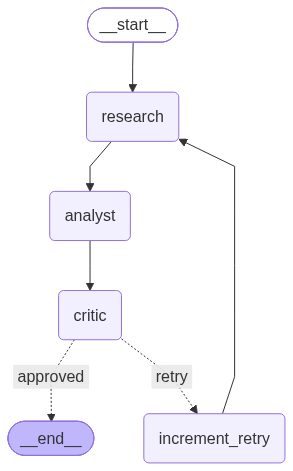

In [ ]:
from IPython.display import Image, display

display(
    Image(
        autonomous_research_graph.get_graph().draw_mermaid_png()
    )
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "autonomous_research_001"
    }
}

result = autonomous_research_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
""",
        "retry_count": 0,
        "max_retries": 2
    },
    config=config
)

print("\n" + "=" * 80)
print("🏁 AUTONOMOUS RESEARCH COMPLETED")
print("=" * 80)


🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10
🔄 Research retry 1/2
🔄 Retry count updated: 1

🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10
🔄 Research retry 2/2
🔄 Retry count updated: 2

🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10
⚠️ Maximum research retries reached.

🏁 AUTONOMOUS RESEARCH COMPLETED


In [ ]:
print("\n📝 FINAL ANSWER\n")
print(result["analysis"].answer)

print("\n📊 CRITIC REVIEW")
print("Approved:", result["critic_review"].approved)
print("Score:", result["critic_review"].score, "/10")

print("\n🔄 Total Retries:")
print(result.get("retry_count", 0))

print("\n⚠️ LIMITATIONS:")
for limitation in result["analysis"].limitations:
    print("-", limitation)


📝 FINAL ANSWER

Based on the evidence provided, both LangGraph and AutoGen are designed for building multi-agent AI applications, but they differ in their approach and strengths. Here's a summary of their key features and how they compare to each other, supported by the evidence from the provided sources (URLs 1-5):

**AutoGen**:
- Designed for making multi-agent conversations easier to build, focusing on LLM-to-LLM and human-in-the-loop interactions.
- Enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate.
- Emphasizes dynamic, event-driven exchanges between agents, making it suitable for complex, collaborative tasks.
- Provides a framework for LLM agent collaboration, which was one of the first frameworks in this space.

**LangGraph**:
- Takes a more workflow-centric, graph-based approach.
- Allows developers to define stateful applications where agents, tools, and retries are connected as nodes in a graph.
- Strong in r

In [ ]:
class QueryRefinement(BaseModel):
    search_queries: list[str] = Field(
        description="Specific web search queries needed to fill gaps in the research"
    )

    reasoning: str = Field(
        description="Why these searches are needed based on the critic feedback"
    )

In [ ]:
query_refiner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are a research query planning agent.

Your job is to improve a research process after a critic
identifies weaknesses.

Generate specific search queries that will help find
missing information.

RULES:

1. Use the critic feedback.
2. Focus on missing information.
3. Generate 2 to 4 highly specific queries.
4. Avoid repeating the original broad question.
5. Prefer official documentation, technical documentation,
   research papers, and authoritative sources when appropriate.
"""
    ),
    (
        "human",
        """
ORIGINAL RESEARCH QUESTION:

{question}


CRITIC FEEDBACK:

{feedback}


MISSING INFORMATION:

{missing_information}


Generate improved search queries.
"""
    )
])

In [ ]:
query_refiner_chain = (
    query_refiner_prompt
    | llm.with_structured_output(QueryRefinement)
)

print("✅ Query Refiner Agent created")

✅ Query Refiner Agent created


In [ ]:
refinement = query_refiner_chain.invoke({
    "question": research_question,
    "feedback": critic_review.feedback,
    "missing_information": "\n".join(
        critic_review.missing_information
    )
})

print("🧠 QUERY REFINEMENT\n")

print("Reasoning:")
print(refinement.reasoning)

print("\nNew Search Queries:")

for i, query in enumerate(refinement.search_queries, 1):
    print(f"{i}. {query}")

🧠 QUERY REFINEMENT

Reasoning:
The search queries are designed to focus on the missing information regarding the effectiveness of LangGraph and AutoGen in real-world applications. They aim to provide a comprehensive comparison of the two systems in state management and multi-agent orchestration, while also emphasizing real-world scenarios.

New Search Queries:
1. Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration
2. Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration
3. Comparative analysis of LangGraph and AutoGen in state management and multi-agent orchestration: real-world effectiveness
4. State management and multi-agent orchestration performance of LangGraph and AutoGen: real-world case studies


In [ ]:
class AutonomousResearchState(TypedDict, total=False):

    question: str

    retrieved_docs: list
    formatted_evidence: str

    analysis: EvidenceAnalysis
    critic_review: CriticReview

    retry_count: int
    max_retries: int

    # New fields
    search_queries: list[str]
    refinement_reasoning: str

In [ ]:
def refine_query_node(state: AutonomousResearchState):

    print("\n🧠 QUERY REFINEMENT NODE STARTED")

    critic = state["critic_review"]

    refinement = query_refiner_chain.invoke({
        "question": state["question"],
        "feedback": critic.feedback,
        "missing_information": "\n".join(
            critic.missing_information
        )
    })

    print("\n🔎 New Queries Generated:")

    for query in refinement.search_queries:
        print("-", query)

    return {
        "search_queries": refinement.search_queries,
        "refinement_reasoning": refinement.reasoning
    }

In [ ]:
test_state = {
    "question": research_question,
    "critic_review": critic_review
}

refined_result = refine_query_node(test_state)

print("\nReturned State:")
print(refined_result)


🧠 QUERY REFINEMENT NODE STARTED

🔎 New Queries Generated:
- Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration
- Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration
- Strengths and weaknesses of LangGraph and AutoGen in state management and multi-agent orchestration: real-world applications
- Case studies of LangGraph and AutoGen in state management and multi-agent orchestration: real-world effectiveness

Returned State:
{'search_queries': ['Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration', 'Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration', 'Strengths and weaknesses of LangGraph and AutoGen in state management and multi-agent orchestration: real-world applications', 'Case studies of LangGraph and AutoGen in state management and multi-agent orchestratio

In [ ]:
def research_with_tavily(queries, max_results=3):

    all_results = []

    for query in queries:

        print(f"\n🌐 Searching: {query}")

        try:

            response = tavily_client.search(
                query=query,
                search_depth="advanced",
                max_results=max_results
            )

            results = response.get("results", [])

            print(f"✅ Found {len(results)} results")

            all_results.extend(results)

        except Exception as e:

            print(f"❌ Search failed: {str(e)}")

    return all_results

In [ ]:
new_search_results = research_with_tavily(
    refined_result["search_queries"],
    max_results=3
)

print("\nTotal new search results:", len(new_search_results))


🌐 Searching: Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration
❌ Search failed: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))

🌐 Searching: Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration
✅ Found 3 results

🌐 Searching: Strengths and weaknesses of LangGraph and AutoGen in state management and multi-agent orchestration: real-world applications
✅ Found 3 results

🌐 Searching: Case studies of LangGraph and AutoGen in state management and multi-agent orchestration: real-world effectiveness
✅ Found 3 results

Total new search results: 9


In [ ]:
def remove_duplicate_urls(search_results):
    
    seen_urls = set()
    unique_results = []

    for result in search_results:
        
        url = result.get("url", "").strip()
        
        if url and url not in seen_urls:
            seen_urls.add(url)
            unique_results.append(result)

    print(f"📊 Original results: {len(search_results)}")
    print(f"✅ Unique URLs: {len(unique_results)}")

    return unique_results

In [ ]:
unique_search_results = remove_duplicate_urls(
    new_search_results
)

print("\nUnique URLs:\n")

for i, result in enumerate(unique_search_results, 1):
    print(f"{i}. {result.get('title')}")
    print(result.get('url'))
    print()

📊 Original results: 9
✅ Unique URLs: 6

Unique URLs:

1. AutoGen vs LangGraph: Comparing Multi-Agent AI Frameworks
https://www.truefoundry.com/blog/autogen-vs-langgraph

2. AutoGen vs LangGraph: The Ultimate Multi-Agent AI Guide
https://vegavid.com/blog/autogen-difference-between-and-langgraph

3. LangGraph vs AutoGen: Comparing AI Agent Frameworks
https://blog.promptlayer.com/langgraph-vs-autogen

4. LangGraph vs AutoGen: How are These LLM Workflow ...
https://www.zenml.io/blog/langgraph-vs-autogen

5. LLM-Based Multi-Agent Orchestration: A Survey of ...
https://www.preprints.org/manuscript/202604.2147

6. LangGraph is Not a True Agentic Framework
https://medium.com/@saeedhajebi/langgraph-is-not-a-true-agentic-framework-3f010c780857



In [ ]:
MAX_NEW_SOURCES = 5

selected_new_results = unique_search_results[:MAX_NEW_SOURCES]

new_urls = [
    result["url"]
    for result in selected_new_results
]

print(f"📄 Selected {len(new_urls)} new sources:\n")

for i, url in enumerate(new_urls, 1):
    print(f"{i}. {url}")

📄 Selected 5 new sources:

1. https://www.truefoundry.com/blog/autogen-vs-langgraph
2. https://vegavid.com/blog/autogen-difference-between-and-langgraph
3. https://blog.promptlayer.com/langgraph-vs-autogen
4. https://www.zenml.io/blog/langgraph-vs-autogen
5. https://www.preprints.org/manuscript/202604.2147


In [ ]:
new_extracted_data = extract_web_content_safe(
    new_urls
)

print("\n" + "=" * 60)
print("NEW EXTRACTION SUMMARY")
print("=" * 60)

print(
    "Successful:",
    len(new_extracted_data["results"])
)

print(
    "Failed:",
    len(new_extracted_data["failed_urls"])
)


📄 Extracting 1/5
URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
✅ Successfully extracted

📄 Extracting 2/5
URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph
✅ Successfully extracted

📄 Extracting 3/5
URL: https://blog.promptlayer.com/langgraph-vs-autogen
✅ Successfully extracted

📄 Extracting 4/5
URL: https://www.zenml.io/blog/langgraph-vs-autogen
✅ Successfully extracted

📄 Extracting 5/5
URL: https://www.preprints.org/manuscript/202604.2147
✅ Successfully extracted

NEW EXTRACTION SUMMARY
Successful: 5
Failed: 0


In [ ]:
new_chunks = chunk_extracted_sources(
    new_extracted_data
)

print(f"\n✂️ Total new chunks created: {len(new_chunks)}")


📄 URL: https://www.truefoundry.com/blog/autogen-vs-langgraph
   Original length: 31056 characters
   Chunks created: 33

📄 URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph
   Original length: 34631 characters
   Chunks created: 38

📄 URL: https://blog.promptlayer.com/langgraph-vs-autogen
   Original length: 15386 characters
   Chunks created: 17

📄 URL: https://www.zenml.io/blog/langgraph-vs-autogen
   Original length: 33209 characters
   Chunks created: 45

📄 URL: https://www.preprints.org/manuscript/202604.2147
   Original length: 164644 characters
   Chunks created: 193

✂️ Total new chunks created: 326


In [ ]:
new_documents = []

for chunk in new_chunks:
    
    document = Document(
        page_content=chunk["content"],
        metadata={
            "url": chunk["url"],
            "chunk_id": chunk["chunk_id"],
            "source": "retry_research"
        }
    )
    
    new_documents.append(document)

print(
    f"✅ Created {len(new_documents)} new documents"
)

✅ Created 326 new documents


In [ ]:
if new_documents:
    
    vectorstore.add_documents(new_documents)
    
    print(
        f"✅ Added {len(new_documents)} documents to Chroma"
    )

else:
    
    print("⚠️ No new documents available to add")

✅ Added 326 documents to Chroma


In [ ]:
if new_documents:
    
    vectorstore.add_documents(new_documents)
    
    print(
        f"✅ Added {len(new_documents)} documents to Chroma"
    )

else:
    
    print("⚠️ No new documents available to add")

✅ Added 326 documents to Chroma


In [ ]:
test_docs = retriever.invoke(research_question)

print(f"📚 Retrieved {len(test_docs)} documents\n")

for i, doc in enumerate(test_docs, 1):
    
    print("=" * 80)
    print(f"DOCUMENT {i}")
    print("=" * 80)
    
    print("URL:", doc.metadata.get("url"))
    print("Source:", doc.metadata.get("source", "initial_research"))
    
    print("\nContent:")
    print(doc.page_content[:700])
    print()

📚 Retrieved 5 documents

DOCUMENT 1
URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph
Source: retry_research

Content:
The Core Difference: In short, AutoGen treats multi-agent interaction as a dynamic conversation (like a group chat of experts), whereas LangGraph treats multi-agent interaction as a state machine (like a strictly defined flowchart of tasks).

## Why It Matters: The Strategic Importance of AI Orchestration

As enterprises scale generative AI, the limitations of standalone models become glaringly apparent. An LLM on its own lacks memory persistence, struggles with complex conditional logic, and cannot independently verify its own work. Orchestration frameworks solve these issues by dividing tasks into smaller, manageable chunks handled by specialized agents.

Understanding the difference betwe

DOCUMENT 2
URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph
Source: retry_research

Content:
The Core Difference: In short, AutoGen trea

In [ ]:
def research_more_node(state: AutonomousResearchState):

    print("\n" + "=" * 80)
    print("🌐 AUTONOMOUS RE-RESEARCH NODE STARTED")
    print("=" * 80)

    # Get refined queries
    queries = state.get("search_queries", [])

    if not queries:
        print("⚠️ No refined queries available.")

        return {}

    print("\n🔎 SEARCH QUERIES:")

    for i, query in enumerate(queries, 1):
        print(f"{i}. {query}")

    # --------------------------------------------------
    # STEP 1: Tavily Search
    # --------------------------------------------------

    print("\n🌐 STEP 1: SEARCHING TAVILY")

    search_results = research_with_tavily(
        queries,
        max_results=3
    )

    if not search_results:
        print("⚠️ No new search results found.")

        return {}

    # --------------------------------------------------
    # STEP 2: Remove duplicate URLs
    # --------------------------------------------------

    print("\n🧹 STEP 2: REMOVING DUPLICATES")

    unique_results = remove_duplicate_urls(
        search_results
    )

    # --------------------------------------------------
    # STEP 3: Select best sources
    # --------------------------------------------------

    print("\n⭐ STEP 3: SELECTING SOURCES")

    MAX_NEW_SOURCES = 5

    selected_results = unique_results[:MAX_NEW_SOURCES]

    urls = [
        result["url"]
        for result in selected_results
        if result.get("url")
    ]

    print(f"Selected {len(urls)} sources")

    # --------------------------------------------------
    # STEP 4: Extract content
    # --------------------------------------------------

    print("\n📄 STEP 4: EXTRACTING WEB CONTENT")

    extracted_data = extract_web_content_safe(urls)

    if not extracted_data.get("results"):
        print("⚠️ No content could be extracted.")

        return {}

    # --------------------------------------------------
    # STEP 5: Chunk content
    # --------------------------------------------------

    print("\n✂️ STEP 5: CHUNKING CONTENT")

    new_chunks = chunk_extracted_sources(
        extracted_data
    )

    if not new_chunks:
        print("⚠️ No chunks created.")

        return {}

    # --------------------------------------------------
    # STEP 6: Convert to Documents
    # --------------------------------------------------

    print("\n📚 STEP 6: CREATING DOCUMENTS")

    new_documents = []

    for chunk in new_chunks:

        document = Document(
            page_content=chunk["content"],
            metadata={
                "url": chunk["url"],
                "chunk_id": chunk["chunk_id"],
                "source": "retry_research"
            }
        )

        new_documents.append(document)

    print(
        f"Created {len(new_documents)} new documents"
    )

    # --------------------------------------------------
    # STEP 7: Add to Chroma
    # --------------------------------------------------

    print("\n🗄️ STEP 7: UPDATING VECTOR DATABASE")

    vectorstore.add_documents(new_documents)

    print("✅ New evidence added to Chroma")

    # --------------------------------------------------
    # STEP 8: Retrieve updated evidence
    # --------------------------------------------------

    print("\n🔍 STEP 8: RETRIEVING UPDATED EVIDENCE")

    updated_docs = retriever.invoke(
        state["question"]
    )

    formatted_evidence = format_retrieved_documents(
        updated_docs
    )

    print(
        f"✅ Retrieved {len(updated_docs)} updated documents"
    )

    print("\n" + "=" * 80)
    print("🎉 AUTONOMOUS RE-RESEARCH COMPLETED")
    print("=" * 80)

    return {
        "retrieved_docs": updated_docs,
        "formatted_evidence": formatted_evidence
    }

In [ ]:
test_state = {
    "question": research_question,
    "search_queries": refined_result["search_queries"]
}

test_research_more = research_more_node(
    test_state
)


🌐 AUTONOMOUS RE-RESEARCH NODE STARTED

🔎 SEARCH QUERIES:
1. Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration
2. Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration
3. Strengths and weaknesses of LangGraph and AutoGen in state management and multi-agent orchestration: real-world applications
4. Case studies of LangGraph and AutoGen in state management and multi-agent orchestration: real-world effectiveness

🌐 STEP 1: SEARCHING TAVILY

🌐 Searching: Real-world applications comparison of LangGraph and AutoGen in state management and multi-agent orchestration
✅ Found 3 results

🌐 Searching: Evaluation of LangGraph and AutoGen in real-world scenarios: state management and multi-agent orchestration
✅ Found 3 results

🌐 Searching: Strengths and weaknesses of LangGraph and AutoGen in state management and multi-agent orchestration: real-world applications
✅ Found 3 results

🌐 Sea

In [ ]:
print("Retrieved documents:")

for i, doc in enumerate(
    test_research_more.get("retrieved_docs", []),
    1
):

    print("\n" + "=" * 70)
    print(f"DOCUMENT {i}")
    print("=" * 70)

    print("URL:", doc.metadata.get("url"))

    print("\nCONTENT:")
    print(doc.page_content[:800])

Retrieved documents:

DOCUMENT 1
URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph

CONTENT:
The Core Difference: In short, AutoGen treats multi-agent interaction as a dynamic conversation (like a group chat of experts), whereas LangGraph treats multi-agent interaction as a state machine (like a strictly defined flowchart of tasks).

## Why It Matters: The Strategic Importance of AI Orchestration

As enterprises scale generative AI, the limitations of standalone models become glaringly apparent. An LLM on its own lacks memory persistence, struggles with complex conditional logic, and cannot independently verify its own work. Orchestration frameworks solve these issues by dividing tasks into smaller, manageable chunks handled by specialized agents.

Understanding the difference between AutoGen and LangGraph matters for several critical business reasons:

DOCUMENT 2
URL: https://vegavid.com/blog/autogen-difference-between-and-langgraph

CONTENT:
The Core Difference: 

In [ ]:
research_builder = StateGraph(
    AutonomousResearchState
)

# Add nodes
research_builder.add_node(
    "research",
    research_node
)

research_builder.add_node(
    "analyst",
    analyst_node
)

research_builder.add_node(
    "critic",
    critic_node
)

research_builder.add_node(
    "increment_retry",
    increment_retry
)

research_builder.add_node(
    "refine_query",
    refine_query_node
)

research_builder.add_node(
    "research_more",
    research_more_node
)

In [ ]:
research_builder.add_edge(
    START,
    "research"
)

research_builder.add_edge(
    "research",
    "analyst"
)

research_builder.add_edge(
    "analyst",
    "critic"
)

In [ ]:
research_builder.add_conditional_edges(
    "critic",
    route_after_critic,
    {
        "approved": END,

        "retry": "increment_retry",

        "max_retries": END
    }
)

In [ ]:
research_builder.add_edge(
    "increment_retry",
    "refine_query"
)

research_builder.add_edge(
    "refine_query",
    "research_more"
)

research_builder.add_edge(
    "research_more",
    "analyst"
)

print("✅ Autonomous retry pipeline connected")

✅ Autonomous retry pipeline connected


In [ ]:
autonomous_research_graph = research_builder.compile(
    checkpointer=checkpointer
)

print("✅ Final Autonomous Research Graph compiled")

✅ Final Autonomous Research Graph compiled


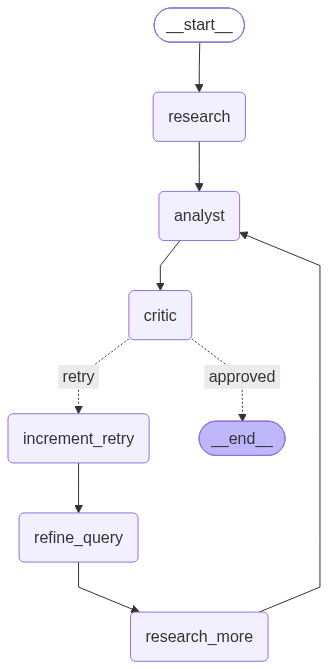

In [ ]:
from IPython.display import Image, display

display(
    Image(
        autonomous_research_graph
        .get_graph()
        .draw_mermaid_png()
    )
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "research_test_002"
    }
}

final_result = autonomous_research_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
""",

        "retry_count": 0,

        "max_retries": 2
    },

    config=config
)


🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10
🔄 Research retry 1/2
🔄 Retry count updated: 1

🧠 QUERY REFINEMENT NODE STARTED

🔎 New Queries Generated:
- Comparison of ease of use for LangGraph and AutoGen in building multi-agent AI applications
- User experience evaluation: LangGraph vs. AutoGen for production-ready multi-agent AI applications
- Ease of use metrics for LangGraph and AutoGen: A comparative analysis
- Comparative study of user interface and workflow for LangGraph and AutoGen in multi-agent AI development

🌐 AUTONOMOUS RE-RESEARCH NODE STARTED

🔎 SEARCH QUERIES:
1. Comparison of ease of use for LangGraph and AutoGen in building multi-agent AI applications
2. User experience evaluation: LangGraph vs. AutoGen for production-ready multi-agent AI applications
3. Ease of use metrics for LangGraph and AutoGen: A comparative analysis
4. Comparative study of user interfac

In [ ]:
print("=" * 90)
print("🏁 FINAL AUTONOMOUS RESEARCH RESULT")
print("=" * 90)

print("\n📝 ANSWER:\n")

print(
    final_result["analysis"].answer
)


print("\n" + "=" * 90)
print("🔍 CRITIC REVIEW")
print("=" * 90)

critic = final_result["critic_review"]

print("Approved:", critic.approved)

print("Score:", critic.score, "/10")

print("\nFeedback:")
print(critic.feedback)


print("\n🔄 Retry Count:")
print(
    final_result.get("retry_count", 0)
)


print("\n⚠️ LIMITATIONS:")

for limitation in final_result["analysis"].limitations:
    print("-", limitation)

🏁 FINAL AUTONOMOUS RESEARCH RESULT

📝 ANSWER:

Based on the evidence provided, both LangGraph and AutoGen are designed to facilitate the building of production-ready multi-agent AI applications, but they differ in their approach and strengths. AutoGen focuses on making multi-agent conversations easier to build, with a particular emphasis on LLM-to-LLM and human-in-the-loop interactions. It enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate. In contrast, LangGraph takes a more workflow-centric, graph-based approach. It allows developers to define stateful applications where agents, tools, and retries are connected as nodes in a graph. This makes LangGraph especially strong for robust, production-grade deployments with loops, error handling, and explicit state management. The evidence does not provide specific comparisons regarding ease of use or best-fit scenarios, so these aspects remain unclear based on the provided sou

In [ ]:
from langgraph.types import interrupt

print("✅ Human interrupt imported successfully")

✅ Human interrupt imported successfully


In [ ]:
def human_approval_node(state: AutonomousResearchState):

    print("\n" + "=" * 80)
    print("👤 WAITING FOR HUMAN APPROVAL")
    print("=" * 80)

    analysis = state["analysis"]
    critic = state["critic_review"]

    human_decision = interrupt({
        "question": state["question"],
        "answer": analysis.answer,
        "critic_score": critic.score,
        "critic_feedback": critic.feedback,
        "limitations": analysis.limitations,
        "message": (
            "Please review the research and choose one of these actions: "
            "'approve', 'research_more', or 'stop'."
        )
    })

    print(f"\n👤 Human decision received: {human_decision}")

    return {
        "human_decision": human_decision
    }

In [ ]:
class AutonomousResearchState(TypedDict, total=False):

    question: str

    # Evidence
    retrieved_docs: list
    formatted_evidence: str

    # Analysis
    analysis: EvidenceAnalysis
    critic_review: CriticReview

    # Retry
    retry_count: int
    max_retries: int

    # Query refinement
    search_queries: list[str]
    refinement_reasoning: str

    # Human-in-the-loop
    human_decision: str

In [ ]:
def route_after_human(state: AutonomousResearchState):

    decision = state.get(
        "human_decision",
        ""
    ).lower().strip()

    if decision == "approve":
        return "approve"

    elif decision == "research_more":
        return "research_more"

    else:
        return "stop"

In [ ]:
human_builder = StateGraph(
    AutonomousResearchState
)

# Add all nodes

human_builder.add_node(
    "research",
    research_node
)

human_builder.add_node(
    "analyst",
    analyst_node
)

human_builder.add_node(
    "critic",
    critic_node
)

human_builder.add_node(
    "human_approval",
    human_approval_node
)

human_builder.add_node(
    "increment_retry",
    increment_retry
)

human_builder.add_node(
    "refine_query",
    refine_query_node
)

human_builder.add_node(
    "research_more",
    research_more_node
)

print("✅ All nodes added")

✅ All nodes added


In [ ]:
human_builder.add_edge(
    START,
    "research"
)

human_builder.add_edge(
    "research",
    "analyst"
)

human_builder.add_edge(
    "analyst",
    "critic"
)

human_builder.add_edge(
    "critic",
    "human_approval"
)

print("✅ Initial workflow connected")

✅ Initial workflow connected


In [ ]:
human_builder.add_conditional_edges(
    "human_approval",
    route_after_human,
    {
        "approve": END,

        "research_more": "increment_retry",

        "stop": END
    }
)

In [ ]:
human_builder.add_edge(
    "increment_retry",
    "refine_query"
)

human_builder.add_edge(
    "refine_query",
    "research_more"
)

human_builder.add_edge(
    "research_more",
    "analyst"
)

print("✅ Human-controlled research loop connected")

✅ Human-controlled research loop connected


In [ ]:
human_research_graph = human_builder.compile(
    checkpointer=checkpointer
)

print("✅ Human-in-the-loop graph compiled")

✅ Human-in-the-loop graph compiled


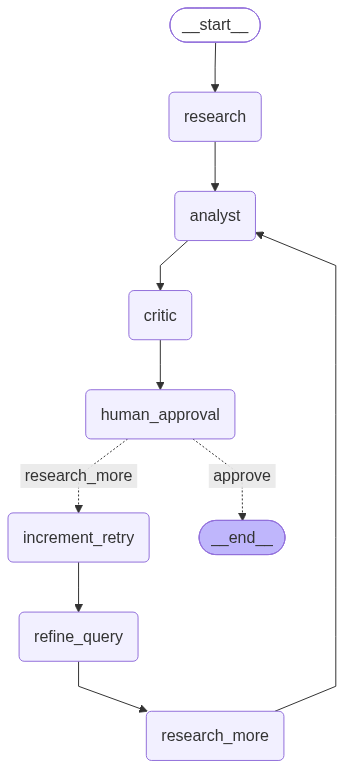

In [ ]:
display(
    Image(
        human_research_graph
        .get_graph()
        .draw_mermaid_png()
    )
)

In [ ]:
from langgraph.types import Command

config = {
    "configurable": {
        "thread_id": "human_research_001"
    }
}

result = human_research_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
""",

        "retry_count": 0,
        "max_retries": 2
    },
    config=config
)

print(result)


🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10

👤 WAITING FOR HUMAN APPROVAL
{'question': '\nCompare LangGraph and AutoGen for building\nproduction-ready multi-agent AI applications.\n', 'retrieved_docs': [Document(id='e58d07d9-549f-41d2-8cfa-493da76ac610', metadata={'url': 'https://www.truefoundry.com/blog/autogen-vs-langgraph', 'chunk_id': 5}, page_content='AutoGen is designed to make multi-agent conversations easier to build, focusing on LLM-to-LLM and human-in-the-loop interactions. It enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate.\n\nLangGraph, on the other hand, takes a more workflow-centric, graph-based approach, letting developers define stateful applications where agents, tools, and retries are connected as nodes in a graph. This makes it especially strong for robust, production-grade deployments wit

In [ ]:
from langgraph.types import Command

result = human_research_graph.invoke(
    Command(
        resume="approve"
    ),
    config=config
)

print("✅ Workflow completed")

Deserializing unregistered type __main__.EvidenceAnalysis from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'EvidenceAnalysis')]
Deserializing unregistered type __main__.CriticReview from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'CriticReview')]



👤 WAITING FOR HUMAN APPROVAL

👤 Human decision received: approve
✅ Workflow completed


In [ ]:
result = human_research_graph.invoke(
    Command(
        resume="research_more"
    ),
    config=config
)


In [ ]:
from langgraph.types import Command
config = {
    "configurable": {
        "thread_id": "human_research_001"
    }
}

result = human_research_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
""",
        "retry_count": 0,
        "max_retries": 2
    },
    config=config
)

print("\n🏁 Graph execution paused or completed.")
print(result)


🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10

👤 WAITING FOR HUMAN APPROVAL

🏁 Graph execution paused or completed.
{'question': '\nCompare LangGraph and AutoGen for building\nproduction-ready multi-agent AI applications.\n', 'retrieved_docs': [Document(id='e58d07d9-549f-41d2-8cfa-493da76ac610', metadata={'url': 'https://www.truefoundry.com/blog/autogen-vs-langgraph', 'chunk_id': 5}, page_content='AutoGen is designed to make multi-agent conversations easier to build, focusing on LLM-to-LLM and human-in-the-loop interactions. It enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate.\n\nLangGraph, on the other hand, takes a more workflow-centric, graph-based approach, letting developers define stateful applications where agents, tools, and retries are connected as nodes in a graph. This makes it especially strong for 

In [ ]:
snapshot = human_research_graph.get_state(config)

print("NEXT NODE:")
print(snapshot.next)

print("\nCURRENT STATE:")
print(snapshot.values)

NEXT NODE:
('human_approval',)

CURRENT STATE:
{'question': '\nCompare LangGraph and AutoGen for building\nproduction-ready multi-agent AI applications.\n', 'retrieved_docs': [Document(id='e58d07d9-549f-41d2-8cfa-493da76ac610', metadata={'url': 'https://www.truefoundry.com/blog/autogen-vs-langgraph', 'chunk_id': 5}, page_content='AutoGen is designed to make multi-agent conversations easier to build, focusing on LLM-to-LLM and human-in-the-loop interactions. It enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate.\n\nLangGraph, on the other hand, takes a more workflow-centric, graph-based approach, letting developers define stateful applications where agents, tools, and retries are connected as nodes in a graph. This makes it especially strong for robust, production-grade deployments with loops, error handling, and explicit state management.\n\nIn this comparison, we’ll explore how AutoGen and LangGraph differ in design phi

In [ ]:
result = human_research_graph.invoke(
    Command(resume="approve"),
    config=config
)

print("✅ Research approved")


👤 WAITING FOR HUMAN APPROVAL

👤 Human decision received: approve
✅ Research approved


In [ ]:
print("\nFINAL ANSWER:\n")
print(result["analysis"].answer)

print("\nCRITIC SCORE:")
print(result["critic_review"].score)

print("\nHUMAN DECISION:")
print(result.get("human_decision"))


FINAL ANSWER:

Based on the evidence provided, both LangGraph and AutoGen are designed to facilitate the building of production-ready multi-agent AI applications, but they differ in their approach and strengths. AutoGen focuses on making multi-agent conversations easier to build, with a particular emphasis on LLM-to-LLM and human-in-the-loop interactions. It enables agents to communicate naturally, delegate tasks, and solve problems collaboratively with minimal boilerplate. In contrast, LangGraph takes a more workflow-centric, graph-based approach. It allows developers to define stateful applications where agents, tools, and retries are connected as nodes in a graph. This makes LangGraph especially strong for robust, production-grade deployments with loops, error handling, and explicit state management. The evidence does not provide specific comparisons regarding ease of use or best-fit scenarios, so these aspects remain unclear based on the provided sources. 

CRITIC SCORE:
2

HUMAN 

In [ ]:
result = human_research_graph.invoke(
    Command(resume="research_more"),
    config=config
)

In [ ]:
class ResearchReport(BaseModel):
    
    title: str = Field(
        description="A professional title for the research report"
    )
    
    executive_summary: str = Field(
        description="A concise summary of the research"
    )
    
    key_findings: list[str] = Field(
        description="The most important evidence-based findings"
    )
    
    detailed_analysis: str = Field(
        description="A detailed analysis answering the research question"
    )
    
    limitations: list[str] = Field(
        description="Limitations and uncertainties in the research"
    )
    
    conclusion: str = Field(
        description="Final evidence-based conclusion"
    )

In [ ]:
report_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are a professional research report writer.

Create a clear, professional, evidence-based report.

RULES:

1. Use ONLY the provided research analysis and findings.
2. Do not invent new facts.
3. Do not add unsupported claims.
4. Write clearly and professionally.
5. Clearly mention research limitations.
6. Make the report useful for technical and professional readers.
"""
    ),
    
    (
        "human",
        """
RESEARCH QUESTION:

{question}


ANALYSIS:

{answer}


KEY FINDINGS:

{findings}


LIMITATIONS:

{limitations}


Create a professional research report.
"""
    )
])

print("✅ Report prompt created")

✅ Report prompt created


In [ ]:
report_chain = (
    report_prompt
    | llm.with_structured_output(ResearchReport)
)

print("✅ Report Generator created")

✅ Report Generator created


In [ ]:
def format_report_findings(findings):
    
    formatted = ""
    
    for i, finding in enumerate(findings, 1):
        
        formatted += f"{i}. {finding.claim}\n"
        
        formatted += (
            f"   Source: "
            f"{finding.supporting_source}\n\n"
        )
    
    return formatted

In [ ]:
report = report_chain.invoke({
    
    "question": research_question,
    
    "answer": analysis.answer,
    
    "findings": format_report_findings(
        analysis.findings
    ),
    
    "limitations": "\n".join(
        f"- {item}"
        for item in analysis.limitations
    )
})

print("✅ Report generated successfully")

✅ Report generated successfully


In [ ]:
print("=" * 80)
print("TITLE")
print("=" * 80)

print(report.title)


print("\n" + "=" * 80)
print("EXECUTIVE SUMMARY")
print("=" * 80)

print(report.executive_summary)


print("\n" + "=" * 80)
print("KEY FINDINGS")
print("=" * 80)

for i, finding in enumerate(report.key_findings, 1):
    print(f"{i}. {finding}")


print("\n" + "=" * 80)
print("DETAILED ANALYSIS")
print("=" * 80)

print(report.detailed_analysis)


print("\n" + "=" * 80)
print("LIMITATIONS")
print("=" * 80)

for limitation in report.limitations:
    print("-", limitation)


print("\n" + "=" * 80)
print("CONCLUSION")
print("=" * 80)

print(report.conclusion)

TITLE
A Comparative Analysis of LangGraph and AutoGen in State Management and Multi-Agent Orchestration

EXECUTIVE SUMMARY
This report provides a detailed analysis of the state management and multi-agent orchestration capabilities of LangGraph and AutoGen, based on the provided research findings. It highlights the key differences in their approaches and features, while also acknowledging the limitations of the available evidence.

KEY FINDINGS
1. LangGraph employs an explicit graph/state machine approach for multi-agent orchestration, with durable, persistent state management via Checkpointers and formalized short-term and long-term memory.
2. AutoGen utilizes a conversation-driven collaboration approach for multi-agent orchestration, leveraging a RAG-focused Memory protocol for state management, which is managed per-agent or per-team and can be saved/loaded manually.
3. LangGraph supports cycles, branching, and parallel execution in its graph-based model, while AutoGen focuses on pred

In [ ]:
def create_markdown_report(report, analysis):

    markdown = f"""# {report.title}

## Executive Summary

{report.executive_summary}


## Research Question

{research_question}


## Key Findings

"""

    for i, finding in enumerate(report.key_findings, 1):
        markdown += f"{i}. {finding}\n"

    markdown += f"""

## Detailed Analysis

{report.detailed_analysis}


## Evidence Sources

"""

    for i, finding in enumerate(analysis.findings, 1):

        markdown += (
            f"{i}. [{finding.supporting_source}]"
            f"({finding.supporting_source})\n"
        )

    markdown += """

## Research Limitations

"""

    for limitation in report.limitations:
        markdown += f"- {limitation}\n"

    markdown += f"""

## Conclusion

{report.conclusion}


---

*Report generated by the Autonomous Research Agent*
"""

    return markdown

In [ ]:
markdown_report = create_markdown_report(
    report,
    analysis
)

print(markdown_report)

# A Comparative Analysis of LangGraph and AutoGen in State Management and Multi-Agent Orchestration

## Executive Summary

This report provides a detailed analysis of the state management and multi-agent orchestration capabilities of LangGraph and AutoGen, based on the provided research findings. It highlights the key differences in their approaches and features, while also acknowledging the limitations of the available evidence.


## Research Question


How do LangGraph and AutoGen differ in state management
and multi-agent orchestration?



## Key Findings

1. LangGraph employs an explicit graph/state machine approach for multi-agent orchestration, with durable, persistent state management via Checkpointers and formalized short-term and long-term memory.
2. AutoGen utilizes a conversation-driven collaboration approach for multi-agent orchestration, leveraging a RAG-focused Memory protocol for state management, which is managed per-agent or per-team and can be saved/loaded manually.
3

In [ ]:
from pathlib import Path

reports_folder = Path("reports")

reports_folder.mkdir(exist_ok=True)

report_path = reports_folder / "research_report.md"

report_path.write_text(
    markdown_report,
    encoding="utf-8"
)

print(f"✅ Markdown report saved at:\n{report_path}")

✅ Markdown report saved at:
reports\research_report.md


In [ ]:
%pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 2.0/2.0 MB 16.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    PageBreak
)

print("✅ ReportLab imported successfully")

✅ ReportLab imported successfully


In [ ]:
from pathlib import Path


def create_pdf_report(
    report,
    analysis,
    question,
    output_path="reports/research_report.pdf"
):
    
    output_path = Path(output_path)
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )
    
    doc = SimpleDocTemplate(
        str(output_path),
        pagesize=A4,
        rightMargin=50,
        leftMargin=50,
        topMargin=50,
        bottomMargin=50
    )
    
    styles = getSampleStyleSheet()
    
    # Custom title style
    title_style = ParagraphStyle(
        "CustomTitle",
        parent=styles["Title"],
        alignment=TA_CENTER,
        fontSize=22,
        spaceAfter=25
    )
    
    heading_style = ParagraphStyle(
        "CustomHeading",
        parent=styles["Heading2"],
        spaceBefore=15,
        spaceAfter=10
    )
    
    normal_style = styles["BodyText"]
    
    story = []
    
    
    # -----------------------------------
    # TITLE
    # -----------------------------------
    
    story.append(
        Paragraph(
            report.title,
            title_style
        )
    )
    
    story.append(
        Spacer(1, 0.3 * inch)
    )
    
    
    # -----------------------------------
    # RESEARCH QUESTION
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Research Question",
            heading_style
        )
    )
    
    story.append(
        Paragraph(
            question,
            normal_style
        )
    )
    
    
    # -----------------------------------
    # EXECUTIVE SUMMARY
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Executive Summary",
            heading_style
        )
    )
    
    story.append(
        Paragraph(
            report.executive_summary,
            normal_style
        )
    )
    
    
    # -----------------------------------
    # KEY FINDINGS
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Key Findings",
            heading_style
        )
    )
    
    for i, finding in enumerate(
        report.key_findings,
        1
    ):
        
        story.append(
            Paragraph(
                f"{i}. {finding}",
                normal_style
            )
        )
        
        story.append(
            Spacer(1, 0.1 * inch)
        )
    
    
    # -----------------------------------
    # DETAILED ANALYSIS
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Detailed Analysis",
            heading_style
        )
    )
    
    story.append(
        Paragraph(
            report.detailed_analysis,
            normal_style
        )
    )
    
    
    # -----------------------------------
    # EVIDENCE SOURCES
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Evidence Sources",
            heading_style
        )
    )
    
    for i, finding in enumerate(
        analysis.findings,
        1
    ):
        
        story.append(
            Paragraph(
                f"{i}. {finding.supporting_source}",
                normal_style
            )
        )
    
    
    # -----------------------------------
    # LIMITATIONS
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Research Limitations",
            heading_style
        )
    )
    
    for limitation in report.limitations:
        
        story.append(
            Paragraph(
                f"• {limitation}",
                normal_style
            )
        )
    
    
    # -----------------------------------
    # CONCLUSION
    # -----------------------------------
    
    story.append(
        Paragraph(
            "Conclusion",
            heading_style
        )
    )
    
    story.append(
        Paragraph(
            report.conclusion,
            normal_style
        )
    )
    
    
    # -----------------------------------
    # FOOTER
    # -----------------------------------
    
    story.append(
        Spacer(1, 0.4 * inch)
    )
    
    story.append(
        Paragraph(
            "Report generated by the Autonomous Research Agent",
            styles["Italic"]
        )
    )
    
    
    # Build PDF
    doc.build(story)
    
    print(
        f"✅ PDF successfully created:\n{output_path}"
    )
    
    return output_path

In [ ]:
pdf_path = create_pdf_report(
    report=report,
    analysis=analysis,
    question=research_question,
    output_path="reports/research_report.pdf"
)

✅ PDF successfully created:
reports\research_report.pdf


In [ ]:
from pathlib import Path

pdf_path = Path(pdf_path)

print("PDF exists:", pdf_path.exists())
print("PDF location:", pdf_path.absolute())
print("File size:", pdf_path.stat().st_size, "bytes")

PDF exists: True
PDF location: d:\Projects\Research agent\reports\research_report.pdf
File size: 4913 bytes


In [ ]:
from IPython.display import FileLink, display

display(
    FileLink(
        str(pdf_path)
    )
)

d:\Projects\Research agent\reports\research_report.pdf

In [ ]:
class AutonomousResearchState(TypedDict, total=False):

    # User question
    question: str

    # Evidence
    retrieved_docs: list
    formatted_evidence: str

    # Analysis
    analysis: EvidenceAnalysis
    critic_review: CriticReview

    # Retry system
    retry_count: int
    max_retries: int

    # Query refinement
    search_queries: list[str]
    refinement_reasoning: str

    # Human approval
    human_decision: str

    # Reports
    markdown_report: str
    markdown_path: str
    pdf_path: str

In [ ]:
from pathlib import Path


def generate_report_node(state: AutonomousResearchState):

    print("\n" + "=" * 80)
    print("📄 REPORT GENERATION NODE STARTED")
    print("=" * 80)

    analysis = state["analysis"]

    # -----------------------------------------
    # STEP 1: Generate structured report
    # -----------------------------------------

    print("\n🧠 STEP 1: GENERATING REPORT CONTENT")

    generated_report = report_chain.invoke({
        "question": state["question"],

        "answer": analysis.answer,

        "findings": format_report_findings(
            analysis.findings
        ),

        "limitations": "\n".join(
            f"- {item}"
            for item in analysis.limitations
        )
    })

    print("✅ Structured report generated")

    # -----------------------------------------
    # STEP 2: Create Markdown
    # -----------------------------------------

    print("\n📝 STEP 2: CREATING MARKDOWN REPORT")

    markdown = create_markdown_report(
        generated_report,
        analysis
    )

    # -----------------------------------------
    # STEP 3: Save Markdown
    # -----------------------------------------

    print("\n💾 STEP 3: SAVING MARKDOWN")

    reports_folder = Path("reports")
    reports_folder.mkdir(exist_ok=True)

    markdown_path = (
        reports_folder / "autonomous_research_report.md"
    )

    markdown_path.write_text(
        markdown,
        encoding="utf-8"
    )

    print(f"✅ Markdown saved: {markdown_path}")

    # -----------------------------------------
    # STEP 4: Generate PDF
    # -----------------------------------------

    print("\n📕 STEP 4: GENERATING PDF")

    pdf_path = create_pdf_report(
        report=generated_report,
        analysis=analysis,
        question=state["question"],
        output_path="reports/autonomous_research_report.pdf"
    )

    print("\n" + "=" * 80)
    print("🎉 REPORT GENERATION COMPLETED")
    print("=" * 80)

    return {
        "markdown_report": markdown,
        "markdown_path": str(markdown_path),
        "pdf_path": str(pdf_path)
    }

In [ ]:
test_report_state = {
    "question": research_question,
    "analysis": analysis
}

report_result = generate_report_node(
    test_report_state
)

print("\n📄 GENERATED FILES:")
print("Markdown:", report_result["markdown_path"])
print("PDF:", report_result["pdf_path"])


📄 REPORT GENERATION NODE STARTED

🧠 STEP 1: GENERATING REPORT CONTENT
✅ Structured report generated

📝 STEP 2: CREATING MARKDOWN REPORT

💾 STEP 3: SAVING MARKDOWN
✅ Markdown saved: reports\autonomous_research_report.md

📕 STEP 4: GENERATING PDF
✅ PDF successfully created:
reports\autonomous_research_report.pdf

🎉 REPORT GENERATION COMPLETED

📄 GENERATED FILES:
Markdown: reports\autonomous_research_report.md
PDF: reports\autonomous_research_report.pdf


In [ ]:
def route_after_human(state: AutonomousResearchState):

    decision = state.get(
        "human_decision",
        ""
    ).lower().strip()

    if decision == "approve":
        return "approve"

    elif decision == "research_more":
        return "research_more"

    else:
        return "stop"

In [ ]:
final_builder = StateGraph(
    AutonomousResearchState
)


# ==========================================
# ADD NODES
# ==========================================

final_builder.add_node(
    "research",
    research_node
)

final_builder.add_node(
    "analyst",
    analyst_node
)

final_builder.add_node(
    "critic",
    critic_node
)

final_builder.add_node(
    "human_approval",
    human_approval_node
)

final_builder.add_node(
    "increment_retry",
    increment_retry
)

final_builder.add_node(
    "refine_query",
    refine_query_node
)

final_builder.add_node(
    "research_more",
    research_more_node
)

final_builder.add_node(
    "generate_report",
    generate_report_node
)


print("✅ All nodes added successfully")

✅ All nodes added successfully


In [ ]:
final_builder.add_edge(
    START,
    "research"
)

final_builder.add_edge(
    "research",
    "analyst"
)

final_builder.add_edge(
    "analyst",
    "critic"
)

final_builder.add_edge(
    "critic",
    "human_approval"
)

print("✅ Main workflow connected")

✅ Main workflow connected


In [ ]:
final_builder.add_conditional_edges(
    "human_approval",
    route_after_human,
    {
        "approve": "generate_report",

        "research_more": "increment_retry",

        "stop": END
    }
)

In [ ]:
final_builder.add_edge(
    "increment_retry",
    "refine_query"
)

final_builder.add_edge(
    "refine_query",
    "research_more"
)

final_builder.add_edge(
    "research_more",
    "analyst"
)

In [ ]:
final_builder.add_edge(
    "generate_report",
    END
)

print("✅ Report generation connected to END")

✅ Report generation connected to END


In [ ]:
final_autonomous_research_graph = final_builder.compile(
    checkpointer=checkpointer
)

print("🎉 FINAL AUTONOMOUS RESEARCH GRAPH COMPILED!")

🎉 FINAL AUTONOMOUS RESEARCH GRAPH COMPILED!


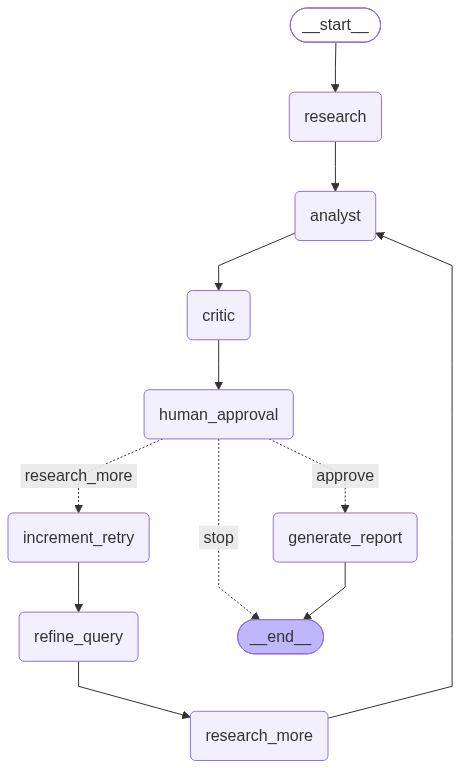

In [ ]:
from IPython.display import Image, display

display(
    Image(
        final_autonomous_research_graph
        .get_graph()
        .draw_mermaid_png()
    )
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "final_research_001"
    }
}

result = final_autonomous_research_graph.invoke(
    {
        "question": """
Compare LangGraph and AutoGen for building
production-ready multi-agent AI applications.
""",

        "retry_count": 0,

        "max_retries": 2
    },
    config=config
)

print("\n⏸️ Execution paused for human approval.")


🔎 RESEARCH NODE STARTED
✅ Retrieved 5 relevant documents

🧠 ANALYST NODE STARTED
✅ Evidence analysis completed

🔍 CRITIC NODE STARTED
📊 Critic Score: 2/10

👤 WAITING FOR HUMAN APPROVAL

⏸️ Execution paused for human approval.


In [ ]:
final_result = final_autonomous_research_graph.invoke(
    Command(resume="approve"),
    config=config
)

print("🎉 Workflow completed!")


👤 WAITING FOR HUMAN APPROVAL

👤 Human decision received: approve

📄 REPORT GENERATION NODE STARTED

🧠 STEP 1: GENERATING REPORT CONTENT
✅ Structured report generated

📝 STEP 2: CREATING MARKDOWN REPORT

💾 STEP 3: SAVING MARKDOWN
✅ Markdown saved: reports\autonomous_research_report.md

📕 STEP 4: GENERATING PDF
✅ PDF successfully created:
reports\autonomous_research_report.pdf

🎉 REPORT GENERATION COMPLETED
🎉 Workflow completed!


In [ ]:
print("📄 MARKDOWN REPORT:")
print(final_result["markdown_path"])

print("\n📕 PDF REPORT:")
print(final_result["pdf_path"])

📄 MARKDOWN REPORT:
reports\autonomous_research_report.md

📕 PDF REPORT:
reports\autonomous_research_report.pdf
